# Cvičenie IV – Kalmanove filtre a priestorové dáta

### Setup and reproducibility

Run the cells from top to bottom. Dependencies are listed in `requirements.txt`. Local copies of the six public teaching datasets are in `data/`; `data/sources.json` records their URLs, download date, and SHA-256 checksums. Missing files are downloaded from the original sources. Paths support both the workspace root and this notebook's directory. No map tiles or online basemap are required.

The Columbus coordinates are supplied local planar coordinates, with no documented CRS in this CSV. They are not assigned an invented EPSG code. NYC geometries use WGS 84 for longitude/latitude and UTM 18N (EPSG:32618) for distances, areas, and nearest neighbors.

In [1]:
from pathlib import Path
from urllib.request import urlopen
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
with warnings.catch_warnings():
    # Static maps do not require the optional Jupyter progress-bar widget.
    warnings.filterwarnings('ignore', message='IProgress not found.*', category=UserWarning)
    import geoplot as gplt
    import libpysal
    import spreg
from libpysal.weights import KNN
from esda.moran import Moran, Moran_Local
from IPython.display import display

data_dir = Path('data')
if not (data_dir / 'sources.json').is_file():
    data_dir = Path('04_exercises/data')
data_dir.mkdir(parents=True, exist_ok=True)
print('Versions:', 'numpy', np.__version__, 'pandas', pd.__version__,
      'geopandas', gpd.__version__, 'libpysal', libpysal.__version__, 'spreg', spreg.__version__)


def cached_file(filename, url):
    path = data_dir / filename
    if not path.is_file():
        with urlopen(url, timeout=90) as response:
            content = response.read()
        if not content:
            raise ValueError(f'Empty download: {url}')
        path.write_bytes(content)
    return path


def load_geoplot(name):
    url = gplt.datasets.get_path(name)
    filename = url.rsplit('/', 1)[-1]
    frame = gpd.read_file(cached_file(filename, url))
    if frame.crs is None:
        raise ValueError(f'No CRS detected for {name}; inspect its source before assigning one.')
    if frame.geometry.isna().any() or frame.geometry.is_empty.any() or not frame.is_valid.all():
        raise ValueError(f'Missing, empty, or invalid geometries in {name}.')
    print(f'{name}: {len(frame)} features; CRS={frame.crs}')
    return frame


def knn_weights(frame, k):
    if len(frame) <= k or not frame.index.is_unique:
        raise ValueError('KNN requires more than k observations and unique row identifiers.')
    coords = np.column_stack([frame.geometry.x, frame.geometry.y])
    if not np.isfinite(coords).all() or len(np.unique(coords, axis=0)) != len(coords):
        raise ValueError('KNN requires finite, distinct coordinates for this exercise.')
    weights = KNN.from_dataframe(frame, k=k, ids=frame.index.to_list(), silence_warnings=True)
    weights.transform = 'R'
    if list(weights.id_order) != frame.index.to_list():
        raise ValueError('Weight ordering differs from the data ordering.')
    np.testing.assert_allclose(np.asarray(weights.sparse.sum(axis=1)).ravel(), 1)
    return weights


def fit_spatial(model_class, y, X, w, **kwargs):
    # NumPy may return zero-imaginary complex eigenvalues for a real symmetric
    # condition-index calculation inside spreg. Suppress only that known cast.
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', category=np.exceptions.ComplexWarning,
                                module=r'spreg\.diagnostics')
        warnings.filterwarnings('ignore', message="Method 'bounded' does not support relative tolerance.*",
                                category=RuntimeWarning, module=r'spreg\.ml_error')
        model = model_class(np.asarray(y, dtype=float).reshape(-1, 1),
                            np.asarray(X, dtype=float), w=w, **kwargs)
    if not np.isfinite(model.betas).all():
        raise ValueError('The spatial model has nonfinite coefficients.')
    return model


def sar_coefficients(model, n_features):
    rho = float(np.asarray(model.rho).item())
    parameters = np.asarray(model.betas)
    if parameters.shape != (n_features + 2, 1) or not np.isclose(parameters[-1, 0], rho):
        raise ValueError('Inspect coefficient order: this solution expects intercept, X betas, rho.')
    if not abs(rho) < 1:
        raise ValueError('Prediction requires an admissible SAR feedback coefficient.')
    return rho, parameters[:-1].copy()


def error_scores(actual, predicted):
    actual, predicted = np.asarray(actual).ravel(), np.asarray(predicted).ravel()
    if actual.shape != predicted.shape or not np.isfinite(predicted).all():
        raise ValueError('Actual and predicted values must match and be finite.')
    error = predicted - actual
    return {'MAE': float(np.mean(np.abs(error))), 'RMSE': float(np.sqrt(np.mean(error ** 2)))}

Versions: numpy 2.5.3 pandas 3.1.0 geopandas 1.2.0 libpysal 4.15.1 spreg 1.9.1


c:\Users\tema0\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


-------------
## Kalmanov filter

Cieľom je pomocou Kalmanovho filtra odhadnúť skrytý stav $x_t$ z pozorovaných hodnôt $y_t$.

Pracuje v dvoch krokoch:

1. Predikcia – na základe predchádzajúceho odhadu predpovedá aktuálny stav.
2. Aktualizácia – po získaní nového pozorovania opraví predikciu pomocou Kalmanovho zisku.

Kalmanov zisk určuje, akú váhu priradíme novej pozorovanej hodnote v porovnaní s predchádzajúcou predikciou.

                               MAE     RMSE
Estimate                                   
Noisy observations        1.134400 1.436835
One-step state prediction 0.668250 0.850845
Filtered state            0.601865 0.771280


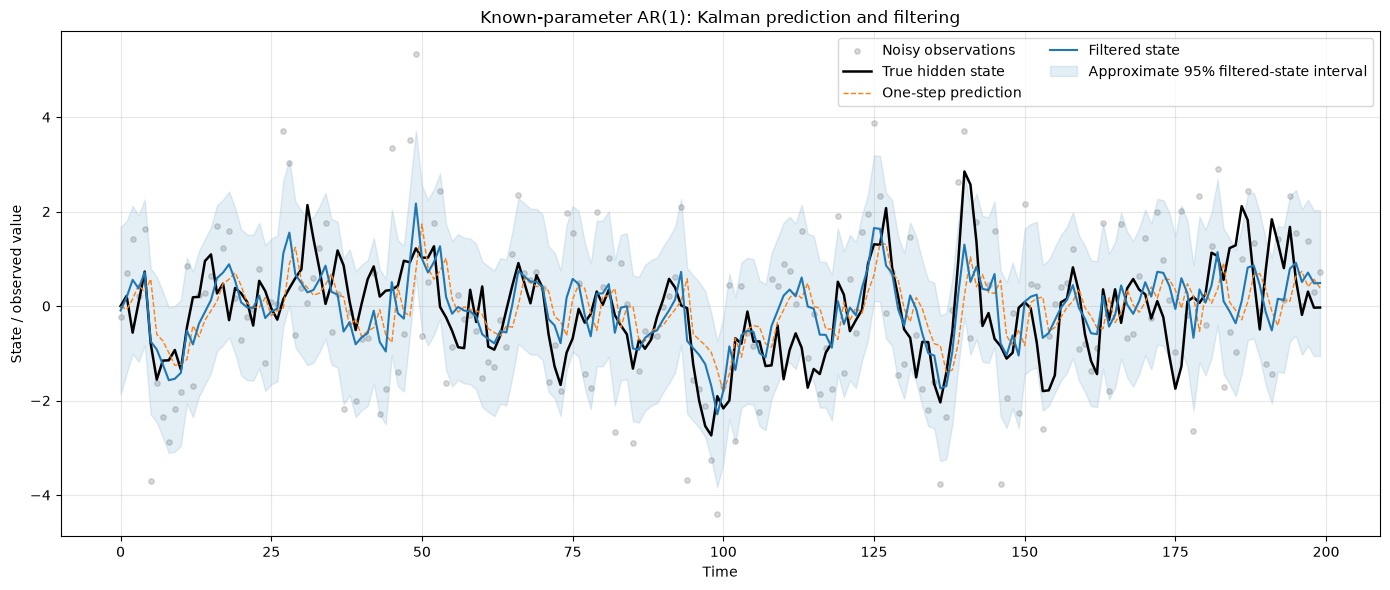

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.kalman_filter import KalmanFilter

# 1. Parametre stavového modelu
rng = np.random.default_rng(42)

# 1. Parametre stavového modelu
n = 200
phi = 0.8
Q = 0.5
R = 2.0

# 2. Simulácia skrytého AR(1) stavu
state = np.zeros(n)

for t in range(1, n):
    w_t = rng.normal(0, np.sqrt(Q))
    state[t] = phi * state[t - 1] + w_t

# 3. Vytvorenie zašumených pozorovaní
v = rng.normal(0, np.sqrt(R), size=n)
observations = state + v

# TODO:
# 1. Vytvorte objekt KalmanFilter pre jednu pozorovanú
#    premennú a jeden skrytý stav.
#
# 2. Odovzdajte filtru zašumené pozorovania observations
#    pomocou metódy bind().
#
# 3. Nastavte matice stavového modelu:
#    - transition: autoregresný koeficient phi,
#    - design: vzťah medzi stavom a pozorovaním = 1,
#    - selection: spôsob vstupu stavového šumu = 1,
#    - state_cov: rozptyl Q,
#    - obs_cov: rozptyl R.
#
# 4. Inicializujte filter s .initialize_known() a .filter()
#   - Počiatočný odhad stavu je 0.
#   - Počiatočná neistota vychádza zo stacionárneho AR(1): [[Q / (1 - phi**2)]].
#
# 5. Získajte predikovaný skrytý stav a filtrovaný skrytý stav.
#
# 6. Vykreslite skutočný stav, Kalmanovu predikciu, zašumené pozorovania
#     a filtrovaný odhad v jednom grafe.

kalman = KalmanFilter(k_endog=1, k_states=1, k_posdef=1)
kalman.bind(np.ascontiguousarray(observations.reshape(-1, 1)))
kalman['transition'] = np.array([[phi]])
kalman['design'] = np.array([[1.0]])
kalman['selection'] = np.array([[1.0]])
kalman['state_cov'] = np.array([[Q]])
kalman['obs_cov'] = np.array([[R]])
kalman.initialize_known(np.array([0.0]), np.array([[Q / (1 - phi ** 2)]]))
kalman_result = kalman.filter()

# predicted_state includes an additional prediction for the next, unobserved time.
predicted_state = kalman_result.predicted_state[0, :n]
filtered_state = kalman_result.filtered_state[0]
filtered_sd = np.sqrt(kalman_result.filtered_state_cov[0, 0, :])
kalman_scores = pd.DataFrame({
    'Noisy observations': error_scores(state, observations),
    'One-step state prediction': error_scores(state, predicted_state),
    'Filtered state': error_scores(state, filtered_state),
}).T.rename_axis('Estimate')
print(kalman_scores.to_string(float_format=lambda value: f'{value:.6f}'))

fig, ax = plt.subplots(figsize=(14, 6))
ax.scatter(range(n), observations, s=15, alpha=0.3, color='gray', label='Noisy observations')
ax.plot(state, color='black', linewidth=1.8, label='True hidden state')
ax.plot(predicted_state, color='tab:orange', linewidth=1, linestyle='--', label='One-step prediction')
ax.plot(filtered_state, color='tab:blue', linewidth=1.5, label='Filtered state')
ax.fill_between(range(n), filtered_state - 1.96 * filtered_sd,
                filtered_state + 1.96 * filtered_sd, alpha=0.12, color='tab:blue',
                label='Approximate 95% filtered-state interval')
ax.set(xlabel='Time', ylabel='State / observed value', title='Known-parameter AR(1): Kalman prediction and filtering')
ax.legend(ncol=2)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


### Exercise 1 — interpretation

The prediction estimates the state at t using observations through t-1. The filtered estimate also incorporates the observation at t; it does not use future observations. Filtering is different from smoothing, which can use later data. The filtered-state uncertainty refers to the latent state, not to a new noisy observation.

The model uses the supplied known phi, Q, and R. The stationary prior variance is `Q/(1-phi**2)` as requested, although this simulation starts the actual state deterministically at zero. Compare the MAE/RMSE against the known simulated truth. A lower error for the filtered estimate demonstrates noise reduction in this simulation; it does not mean every individual filtered value is closer to truth.

**Reference results:** the noisy observations have RMSE **1.436835**, one-step state predictions **0.850845**, and filtered states **0.771280**. The filtered estimate is the most accurate of these three estimates in this seeded simulation.

--------
## Priestorové dáta

Kde sa javy dejú?

* Analýza hustoty zaľudnenia, šírenie infekcií, monitorovanie mobility či pohybu zveri.

Dva základné typy:

1. Vektory (Vector data): Body, čiary alebo polygóny
    
2. Rastre (Raster data)



usa_cities: 3666 features; CRS=EPSG:4326
dc_roads: 3447 features; CRS=EPSG:4326
nyc_boroughs: 5 features; CRS=EPSG:4326


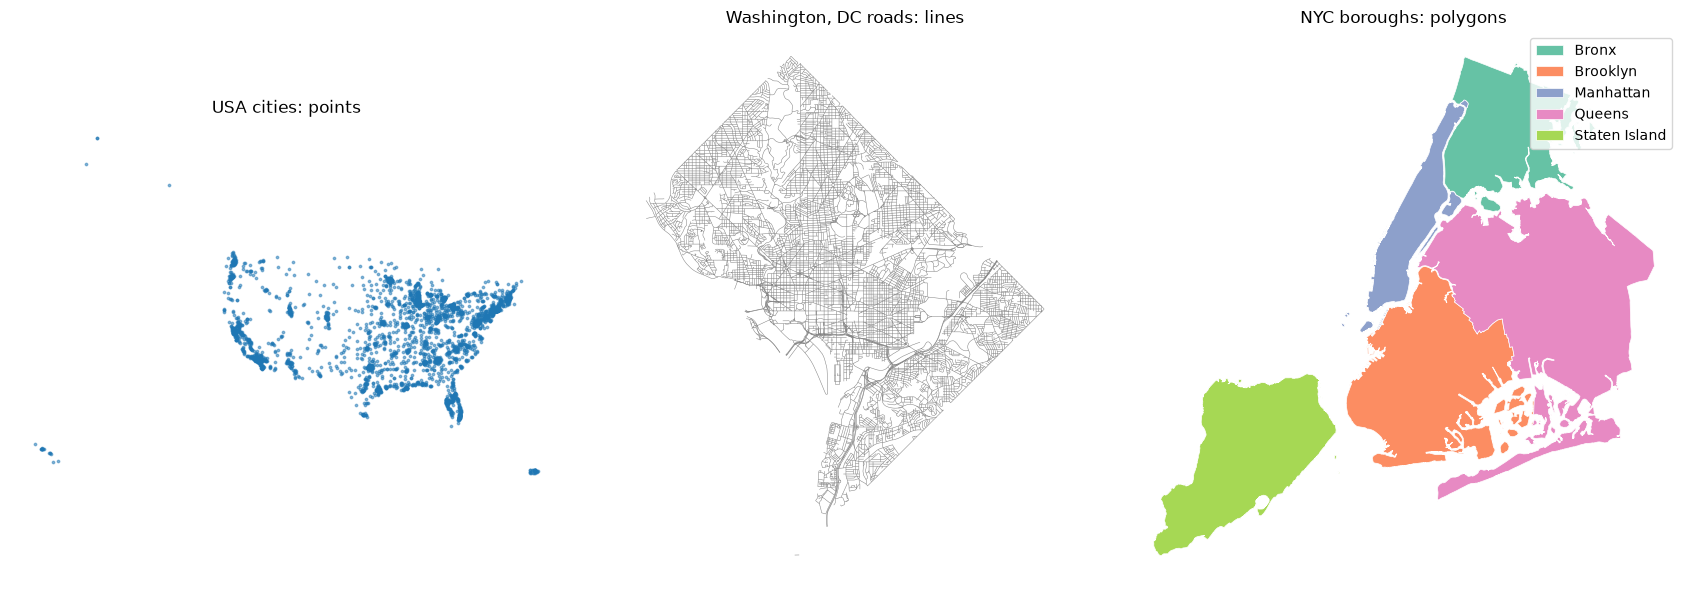

Raster: bands 1 shape (1024, 1024) CRS EPSG:3857 resolution (9.5546285343, 9.5546285343) bounds BoundingBox(left=-11858134.818413004, bottom=4803914.3530251775, right=-11848350.87879388, top=4813698.2926443005)


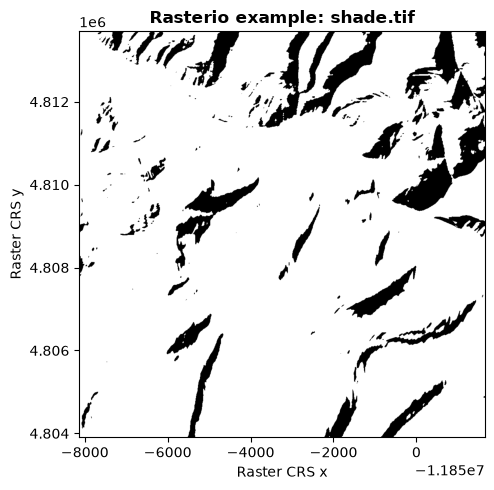

In [3]:
import matplotlib.pyplot as plt
import geopandas as gpd
import geoplot as gplt
import numpy as np
import rasterio
from rasterio.plot import show

# TODO:
# 1. Vykreslite nasledujuce datasety na grafe
#   - usa_cities, dc_roads, nyc_boroughs z knižnice geoplot
#   - 'https://github.com/rasterio/rasterio/raw/main/tests/data/shade.tif' pomocou rasterio.open

usa_cities = load_geoplot('usa_cities')
dc_roads = load_geoplot('dc_roads')
nyc_boroughs = load_geoplot('nyc_boroughs')

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
usa_cities.plot(ax=axes[0], color='tab:blue', markersize=3, alpha=0.5)
dc_roads.plot(ax=axes[1], color='tab:gray', linewidth=0.35)
nyc_boroughs.plot(ax=axes[2], column='BoroName', categorical=True, legend=True,
                   edgecolor='white', linewidth=0.5, cmap='Set2')
for ax, title in zip(axes, ['USA cities: points', 'Washington, DC roads: lines', 'NYC boroughs: polygons']):
    ax.set_title(title)
    ax.set_axis_off()
fig.tight_layout()
plt.show()

raster_path = cached_file('shade.tif', 'https://github.com/rasterio/rasterio/raw/main/tests/data/shade.tif')
with rasterio.open(raster_path) as raster:
    print('Raster:', 'bands', raster.count, 'shape', raster.shape,
          'CRS', raster.crs, 'resolution', raster.res, 'bounds', raster.bounds)
    fig, ax = plt.subplots(figsize=(10, 5))
    show(raster, ax=ax, cmap='gray', title='Rasterio example: shade.tif')
    ax.set_xlabel('Raster CRS x')
    ax.set_ylabel('Raster CRS y')
    fig.tight_layout()
    plt.show()


### Exercise 2 — interpretation

Cities are point vectors, roads are line vectors, and borough boundaries are polygon vectors. The TIFF is a raster: values are attached to grid cells rather than individual geometries. Its printed metadata specifies its own CRS and pixel size; these are not assumed to match the NYC vectors. GeoPlot supplies the vector dataset URLs; GeoPandas plots them directly without needing a remote basemap.

* **Reprojekcia CRS**: 
  * Prevod súradníc z uhlových stupňov GPS (WGS 84) do metrického systému, aby sme mohli počítať reálne vzdialenosti a plochy v metroch.

* **Buffer (Obalová zóna)**:
  * Vytvorenie plošného polygónu okolo bodu, línie alebo plochy v zadanom polomere.

* **Intersection / Prienik**: 
  * Geometrické orezanie dvoch vrstiev, ktoré zachová iba územie, kde sa obe vrstvy navzájom prekrývajú.

* **Spatial Join**: 
  * Priestorový VLOOKUP, ktorý prepojí dve tabuľky na základe toho, či do seba ich geometrie v priestore fyzicky spadajú.

* **Change of Spatial Support (Zmena supportu)**: 
  * Zmena geometrickej mierky dát – napríklad agregácia tisícov izolovaných bodov do plošného súhrnu za celé polygóny.

* **MAUP (Modifiable Areal Unit Problem)**: 
  * Štatistické skreslenie, pri ktorom výsledky analýzy zásadne závisia od toho, aké veľké a aké tvary hraníc zvolíme pre agregáciu dát.


nyc_collision_factors: 7303 features; CRS=EPSG:4326
Original CRS: boroughs EPSG:4326 ; collisions EPSG:4326
Estimated metric CRS: EPSG:32618
Manhattan: 0.006307 square degrees (not a physical area); 59.092 km² in UTM.
Times Square → Wall Street: 0.056245 degrees; 6.010 km straight-line in UTM.
Land represented by NYC borough polygons inside the 5 km buffer (km²):
BoroName
Staten Island    0.0000
Queens           7.8203
Brooklyn         3.3196
Manhattan       33.8544
Bronx            0.0000


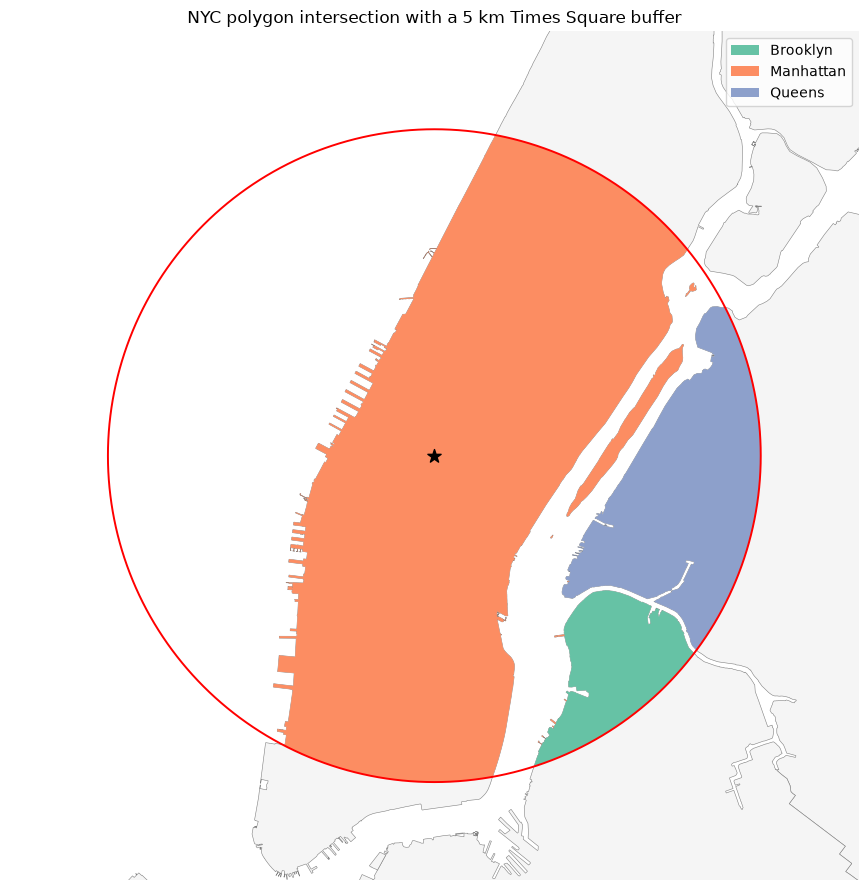

Unassigned points (outside polygons or strictly on a boundary): 5
     BoroName  Accidents  Area_km2  Accidents_per_km2
Staten Island        256   150.758              1.698
       Queens       2433   283.194              8.591
     Brooklyn       2416   181.927             13.280
    Manhattan       1611    59.092             27.263
        Bronx        582   110.196              5.281


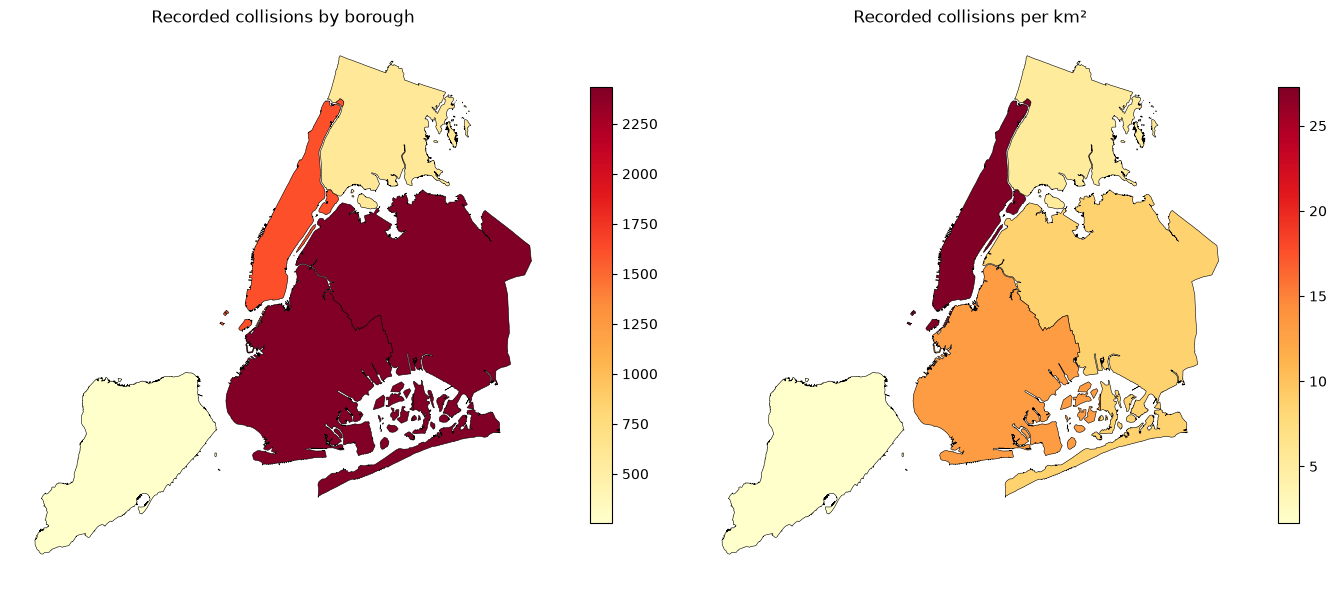

In [4]:
# TODO:
# 1. Načítanie dát a kontrola CRS:
#    - Načítajte polygóny mestských častí (nyc_boroughs) a body nehôd (nyc_collision_factors) cez geoplot
#    - Skontrolujte ich pôvodné CRS (.crs)
#    - Reprojektujte obe vrstvy do metrického systému UTM zóna 18N (EPSG:32618) pomocou .estimate_utm_crs() a .to_crs()
#    - Porovnajte výpočet plochy Manhattanu (.area) a výpočet vzdialenosti (.distance) Times Square -> Wall Street 
#       na pôvodných a reprojektovaných dátach
#
# 2. Intersection a Sjoin:
#    - Vytvorte referenčný bod pre Times Square (lon=-73.9855, lat=40.7580) v EPSG:4326 a reprojektujte do UTM 18N
#    - Vytvorte 5 km zónu pomocou .buffer()
#    - Pomocou gpd.overlay({data}, {buffer}, how='intersection') orežte kruh na skutočnú pevninu NYC a vykreslite výsledok na grafe
#    - Vypíšte rozlohu pevniny v kruhu pre jednotlivé mestské časti (Manhattan, Queens, Brooklyn)
#    - Spojte body nehôd so štvrťami pomocou gpd.sjoin(..., predicate='within')
#    - Agregujte celkový počet nehôd podľa štvrtí (groupby('BoroName').size()) a vykreslite výsledok na grafe
#    - Vypočítajte hustotu nehôd na km² pre všetky štvrte a vykreslite výsledok na grafe

nyc_collisions = load_geoplot('nyc_collision_factors')
print('Original CRS:', 'boroughs', nyc_boroughs.crs, '; collisions', nyc_collisions.crs)
estimated_utm = nyc_boroughs.estimate_utm_crs()
print('Estimated metric CRS:', estimated_utm)
if estimated_utm.to_epsg() != 32618:
    raise ValueError('Inspect the data extent: the assignment expects UTM 18N.')
nyc_utm = nyc_boroughs.to_crs(estimated_utm)
collisions_utm = nyc_collisions.to_crs('EPSG:32618')
nyc_wgs84 = nyc_boroughs.to_crs('EPSG:4326')

landmarks = gpd.GeoDataFrame(
    {'Name': ['Times Square', 'Wall Street (reference point)']},
    geometry=gpd.points_from_xy([-73.9855, -74.0090], [40.7580, 40.7069]), crs='EPSG:4326',
)
landmarks_utm = landmarks.to_crs('EPSG:32618')
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Geometry is in a geographic CRS.*', category=UserWarning)
    area_degrees = nyc_wgs84.loc[nyc_wgs84.BoroName.eq('Manhattan')].area.sum()
    distance_degrees = landmarks.geometry.iloc[[0]].distance(landmarks.geometry.iloc[1]).iloc[0]
area_km2 = nyc_utm.loc[nyc_utm.BoroName.eq('Manhattan')].area.sum() / 1e6
distance_km = landmarks_utm.geometry.iloc[0].distance(landmarks_utm.geometry.iloc[1]) / 1000
print(f'Manhattan: {area_degrees:.6f} square degrees (not a physical area); {area_km2:.3f} km² in UTM.')
print(f'Times Square → Wall Street: {distance_degrees:.6f} degrees; {distance_km:.3f} km straight-line in UTM.')

times_square_buffer = gpd.GeoDataFrame({'Radius_m': [5000]},
    geometry=landmarks_utm.geometry.iloc[[0]].buffer(5000, quad_segs=64).reset_index(drop=True),
    crs=nyc_utm.crs)
land_in_circle = gpd.overlay(nyc_utm[['BoroName', 'geometry']], times_square_buffer,
                             how='intersection', keep_geom_type=True)
land_in_circle['Land_km2'] = land_in_circle.area / 1e6
buffer_areas = land_in_circle.groupby('BoroName')['Land_km2'].sum().reindex(nyc_utm.BoroName, fill_value=0)
print('Land represented by NYC borough polygons inside the 5 km buffer (km²):')
print(buffer_areas.to_string(float_format=lambda value: f'{value:.4f}'))

fig, ax = plt.subplots(figsize=(9, 9))
nyc_utm.plot(ax=ax, color='whitesmoke', edgecolor='gray', linewidth=0.4)
land_in_circle.plot(ax=ax, column='BoroName', categorical=True, cmap='Set2', legend=True)
times_square_buffer.boundary.plot(ax=ax, color='red', linewidth=1.4, label='5 km radius')
landmarks_utm.iloc[[0]].plot(ax=ax, color='black', marker='*', markersize=100)
xmin, ymin, xmax, ymax = times_square_buffer.total_bounds
ax.set_xlim(xmin - 1500, xmax + 1500)
ax.set_ylim(ymin - 1500, ymax + 1500)
ax.set_title('NYC polygon intersection with a 5 km Times Square buffer')
ax.set_axis_off()
fig.tight_layout()
plt.show()

collision_borough_join = gpd.sjoin(collisions_utm, nyc_utm[['BoroName', 'geometry']],
                                  how='left', predicate='within')
if not collision_borough_join.index.is_unique:
    raise ValueError('Some collisions joined to multiple borough polygons.')
borough_counts = collision_borough_join.groupby('BoroName').size()
unassigned_collisions = int(collision_borough_join['BoroName'].isna().sum())
borough_stats = nyc_utm[['BoroName', 'geometry']].copy()
borough_stats['Accidents'] = borough_stats.BoroName.map(borough_counts).fillna(0).astype(int)
borough_stats['Area_km2'] = borough_stats.area / 1e6
borough_stats['Accidents_per_km2'] = borough_stats.Accidents / borough_stats.Area_km2
print(f'Unassigned points (outside polygons or strictly on a boundary): {unassigned_collisions}')
print(borough_stats.drop(columns='geometry').to_string(index=False, float_format=lambda value: f'{value:.3f}'))

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, column, title in zip(axes, ['Accidents', 'Accidents_per_km2'],
                             ['Recorded collisions by borough', 'Recorded collisions per km²']):
    borough_stats.plot(ax=ax, column=column, cmap='YlOrRd', edgecolor='black', linewidth=0.4,
                       legend=True, legend_kwds={'shrink': 0.65})
    ax.set_title(title)
    ax.set_axis_off()
fig.tight_layout()
plt.show()


### Exercise 3 — interpretation

Longitude/latitude coordinates are angles. Their raw `.area` and `.distance` calculations produce square degrees and degrees, not km² or km. Projecting both layers to UTM 18N permits a 5000 m buffer and meaningful local distances and areas. The Times Square–Wall Street calculation is a straight-line distance between declared reference coordinates, not a road-route distance.

Intersection retains only the buffer portions covered by the supplied borough polygons. A spatial join attributes points by geometry, independently of the source's text BOROUGH field. `within` excludes points exactly on polygon boundaries; the count of unassigned points is reported rather than silently allocated. The borough totals plus unassigned points must equal the number of source collisions.

Density divides recorded collisions by polygon area. It is not population-, traffic-, or exposure-adjusted accident risk. The GeoPlot collision dataset is a selected **2016 teaching sample**, containing two first-vehicle contributing-factor categories. Its counts and proportions describe this sample, not all NYC crashes. Aggregating by borough versus ZIP changes spatial support and can change apparent patterns (MAUP).

**Reference results:** Manhattan's represented area is **59.092 km²**, and the landmark distance is **6.010 km**. The 5 km buffer includes **33.8544 km²** of Manhattan, **7.8203 km²** of Queens, and **3.3196 km²** of Brooklyn. Five of 7303 collision points are unassigned by the strict `within` join. Queens has the largest sample count (2433), while Manhattan has the highest count per km² (27.263); count and density therefore identify different maxima.

## Priestorová autokorelácia

Miera toho, či sa podobné hodnoty v priestore zhlukujú (napr. bohaté štvrte vedľa bohatých), alebo sú rozmiestnené náhodne.

![Typy priestorovej autokorelácie](imgs/spatial_autocorrelation_types.png)


* **Negatívna** autokorelácia: Susedia vykazujú systematicky odlišné hodnoty – vysoké hodnoty sú obklopené nízkymi a naopak.
* **Žiadna** autokorelácia: Hodnoty sú rozmiestnené náhodne - priestorová nezávislosť.
* **Pozitívna** autokorelácia: Podobné hodnoty sa zhlukujú vedľa seba.

---

### Globálna priestorová autokorelácia a Globálne Moranovo $I$
Meria lineárnu závislosť medzi hodnotou v lokalite ($y$) a priemernou hodnotou u jej susedov ($Wy$):
* **$I > 0$ (do $+1$):** Pozitívna autokorelácia — podobné hodnoty sa zhlukujú (vysoké s vysokými, nízke s nízkymi).
* **$I \approx 0$:** Nulová autokorelácia — priestorová náhodnosť, hodnoty sú rozmiestnené nezávisle bez akéhokoľvek vzoru.
* **$I < 0$ (do $-1$, vľavo):** Negatívna autokorelácia — šachovnicové striedanie, kde susedia majú systematicky opačné hodnoty.

---

### Lokálna priestorová autokorelácia a Lokálne Moranovo $I$
Lokálne Moranovo $I$ sa počíta pre každú jednotlivú lokalitu, vďaka čomu identifikuje konkrétne územia, ktoré významne prispievajú k celkovej priestorovej autokorelácii. 

Zatrieďuje štatisticky významné lokality ($p < 0.05$) do 4 typov (kvadrantov):

* **HH (High-High) – Hotspot:** Vysoká hodnota obklopená vysokými hodnotami (napr. štvrť s vysokou kriminalitou uprostred iných nebezpečných štvrtí).
* **LL (Low-Low) – Coldspot:** Nízka hodnota obklopená nízkymi hodnotami (napr. pokojná, bezpečná rezidenčná zóna).
* **HL (High-Low) – Priestorový outlier:** Vysoká hodnota obklopená nízkymi hodnotami (ojedinelé problematické ohnisko v inak pokojnom regióne).
* **LH (Low-High) – Priestorový outlier:** Nízka hodnota obklopená vysokými hodnotami (bezpečná enkláva obklopená vysokou kriminalitou).


Columbus n=49, k=8, row-standardized weights; components=1.
Global Moran I=0.436691; E[I]=-0.020833; permutation p=0.000100 (9999 permutations).
Significant positive clustering at 5%: True


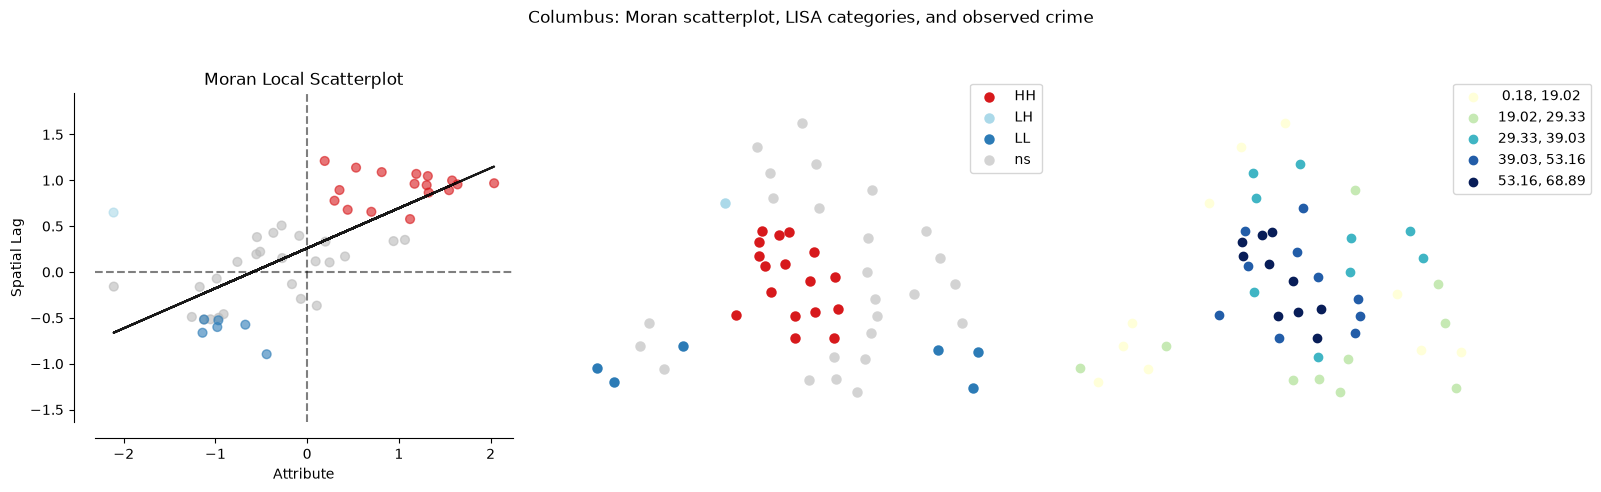

Local categories at unadjusted p < 0.05:
LISA_cluster
HH                 17
LL                  6
HL                  0
LH                  1
Not significant    25
Significant after Benjamini-Hochberg FDR adjustment: 15


,POLYID,CRIME,LISA_cluster,LISA_p,LISA_FDR_significant
23,24,38.30,HH,0.0001,True
17,18,43.96,HH,0.0002,True
27,28,56.92,HH,0.0002,True
29,30,68.89,HH,0.0003,True
14,15,48.59,HH,0.0005,True
15,16,54.84,HH,0.0006,True
24,25,61.30,HH,0.0008,True
10,11,62.28,HH,0.0010,True
18,19,54.52,HH,0.0010,True
11,12,56.71,HH,0.0012,True


In [5]:
# TODO:
# 1. Načítanie dát a príprava GeoDataFrame:
#    - Načítajte súbor 'columbus.csv' z DATA_URL pomocou pd.read_csv (skiprows=1, header=None, names=FULL_COLUMNS)
#    - Vytvorte bodovú geometriu zo stĺpcov súradníc 'X' a 'Y' pomocou gpd.points_from_xy() a zabaľte do GeoDataFrame
#
# 2. Priestorové váhy (Spatial Weights):
#    - Zostrojte maticu priestorových váh pre 8 najbližších susedov pomocou KNN(pracujeme s bodovými dátami/centroidami)
#    - Aplikujte riadkovú normalizáciu váh (weights.transform = 'R')
#
# 3. Globálne Moranovo I:
#    - Vypočítajte globálne Moranovo I pre premennú kriminality 'CRIME'
#    - Vypíšte hodnotu koeficientu Moranovho I a p-hodnotu a zhodnoťte, 
#       či premenná vykazuje priestorové zhlukovanie a či je výsledok štatisticky významný
#
# 4. Lokálne Moranovo I a vizualizácia zhlukov:
#    - Vypočítajte lokálne Moranovo I pre atribút 'CRIME'
#    - Pomocou funkcie plot_local_autocorrelation zo splot.esda vykreslite LISA analýzu na hladine významnosti p=0.05
#    - Zhodnoťte identifikované hotspoty (High-High), coldspoty (Low-Low) a priestorové odľahlé body

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import libpysal
from esda.moran import Moran, Moran_Local

# 1. Načítanie dát mesta Columbus
DATA_URL = (
    "https://raw.githubusercontent.com/GeoDaCenter/GeoDaSpace/master/"
    "econometrics/examples/columbus.csv"
)

FULL_COLUMNS = ['AREA', 'PERIMETER', 'COLUMBUS_', 'COLUMBUS_I', 'POLYID', 'NEIG',
                'HOVAL', 'INC', 'CRIME', 'OPEN', 'PLUMB', 'DISCBD', 'X', 'Y',
                'NSA', 'NSB', 'EW', 'CP', 'THOUS', 'NEIGNO']
columbus_path = cached_file('columbus.csv', DATA_URL)
columbus_frame = pd.read_csv(columbus_path, skiprows=1, header=None, names=FULL_COLUMNS)
if columbus_frame.shape != (49, 20) or columbus_frame.isna().any().any():
    raise ValueError('Expected 49 complete Columbus observations with 20 columns.')
data = gpd.GeoDataFrame(columbus_frame,
                        geometry=gpd.points_from_xy(columbus_frame.X, columbus_frame.Y))
# X/Y are the dataset's local planar coordinates; no undocumented CRS is assigned.
weights = knn_weights(data, k=8)
np.random.seed(42)
moran_global = Moran(data.CRIME.to_numpy(), weights, permutations=9999)
moran_local = Moran_Local(data.CRIME.to_numpy(), weights, permutations=9999, seed=42, n_jobs=1)
print(f'Columbus n={len(data)}, k=8, row-standardized weights; components={weights.n_components}.')
print(f'Global Moran I={moran_global.I:.6f}; E[I]={moran_global.EI:.6f}; '
      f'permutation p={moran_global.p_sim:.6f} (9999 permutations).')
print('Significant positive clustering at 5%:', bool(moran_global.I > moran_global.EI and moran_global.p_sim < 0.05))

from splot.esda import plot_local_autocorrelation
from statsmodels.stats.multitest import multipletests
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=np.exceptions.ComplexWarning,
                            module=r'spreg\.diagnostics')
    fig, axes = plot_local_autocorrelation(moran_local, data, 'CRIME', p=0.05, figsize=(16, 5))
fig.suptitle('Columbus: Moran scatterplot, LISA categories, and observed crime')
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

quadrant_names = {1: 'HH', 2: 'LH', 3: 'LL', 4: 'HL'}
data['LISA_quadrant'] = pd.Series(moran_local.q, index=data.index).map(quadrant_names)
data['LISA_p'] = moran_local.p_sim
data['LISA_cluster'] = np.where(data.LISA_p < 0.05, data.LISA_quadrant, 'Not significant')
data['LISA_FDR_significant'] = multipletests(data.LISA_p, alpha=0.05, method='fdr_bh')[0]
lisa_counts = data.LISA_cluster.value_counts().reindex(['HH', 'LL', 'HL', 'LH', 'Not significant'], fill_value=0)
print('Local categories at unadjusted p < 0.05:')
print(lisa_counts.to_string())
print('Significant after Benjamini-Hochberg FDR adjustment:', int(data.LISA_FDR_significant.sum()))
display(data[['POLYID', 'CRIME', 'LISA_cluster', 'LISA_p', 'LISA_FDR_significant']].sort_values('LISA_p').head(15))


### Exercise 4 — interpretation

Global Moran's I compares crime values with the weighted values at their eight nearest neighbors. Row standardization makes each spatial lag a neighbor average. The randomization reference expectation is `-1/(n-1)`, rather than exactly zero. Unlike a Pearson correlation, Moran's I does not generally have universal bounds of -1 and +1; attainable bounds depend on the weight matrix.

The reported permutation p-value and observed statistic assess clustering relative to random spatial relabelings under that reference model. They do not measure a causal neighbor effect. Local HH/LL categories are hotspots/coldspots; HL/LH are local outliers. The printed counts and POLYID table identify what is actually detected. The requested map uses unadjusted p < 0.05 and is exploratory; the additional FDR column accounts for multiple local comparisons.

**Reference results:** Moran's I is **0.436691** with permutation p = **0.0001**, supporting positive spatial clustering. At unadjusted 5%, there are **17 HH**, **6 LL**, **1 LH**, and **0 HL** locations; 25 are not significant. After FDR adjustment, 15 local tests remain significant. The maps show a central high-crime cluster and surrounding lower-crime observations, with the one LH observation marking a low value near higher neighboring values.

## Priestorové modely: SLX, SAR, SEM a SDM

Keď OLS regresia vykazuje priestorovú autokoreláciu v rezíduách, nasadzujeme priestorové modely. Každý však rieši odlišný vecný mechanizmus:

| Model | Priestorová zložka | Mechanizmus | Kedy použiť |
| :--- | :--- | :--- | :--- | 
| **OLS** | Žiadna | Predpokladá, že rezíduá sú nezávislé. | Keď rezíduá nevykazujú priestorovú autokoreláciu (susedia sa neovplyvňujú). |
| **SLX** *(Spatial Lag of X)* | $WX$ (lagované prediktory) | K bežným vysvetľujúcim premenným ($X$) pridáva do regresie aj ich priestorové lagy u susedov ($WX$) | Pri lokálnom prelievaní vlastností susedov (napr. bohatstvo susedov vplýva na moju lokalitu). |
| **SAR** *(Spatial Lag)* | $Wy$ (lagovaný výsledok) | Do modelu pridáva priestorový lag samotnej závislej premennej ($Wy$). Analógia k autoregresným modelom (AR) v časových radoch. | Na rozdiel od SLX sa tu vplyvy neobmedzujú len na susedov, ale vďaka spätnej väzbe sa šíria cez celý systém  |
| **SEM** *(Spatial Error Model)* | $Wu$ (lagovaná chyba) | Nepozorované vplyvy a šoky sú priestorovo závislé. | Keď priestorovú štruktúru spôsobujú vynechané nepozorované faktory alebo spoločné šoky. |
| **SDM** *(Spatial Durbin Model)* | $Wy$ aj $WX$ | Používa sa spätná väzba medzi výsledkami aj charakteristiky susedov. | Keď pôsobí šírenie výsledku ($Wy$) aj vplyv charakteristík susedov ($WX$) súčasne. |



Prítomnosť priestorovej autokorelácie možno overiť Moranovým testom aplikovaným na rezíduá štandardnej OLS regresie. Tento všeobecný test nás však iba upozorní na existenciu priestorovej závislosti, ale neurčuje, ktorý konkrétny model zvoliť. Pre model s priestorovým lagom prediktorov (SLX) neexistuje špeciálny test; overuje sa klasickým $F$-testom lineárnych obmedzení porovnávajúcim model s lagmi $WX$ a bez nich.

Pre voľbu medzi modelom s priestorovým lagom výsledku (SAR) a modelom s priestorovou chybou (SEM) slúžia špecializované testy Lagrangeových multiplikátorov (LM testy), ktoré sa vyhodnocujú po odhade OLS. Ak je štatisticky významný iba klasický test LM(lag), volíme model SAR (priestorový lag). V opačnom prípade, ak je významný iba LM(error), je správnou voľbou model SEM (priestorová chyba).

### Postup výberu priestorového modelu

1. **Odhadneme OLS s diagnostikou**:
   - Ak **Moranovo I rezíduí nie je signifikantné** (\(p \geq 0.05\)) → nemáme dostatok dôkazov o priestorovej autokorelácii. **OLS môže byť postačujúci**.
   - Ak **je signifikantné** (\(p < 0.05\)) → rezíduá vykazujú priestorovú autokoreláciu a pomocou **LM testov** skúmame vhodný priestorový model.

2. **Rozhodovací strom podľa LM testov:**
   - **Ani jeden LM test nie je signifikantný** → OLS zostáva vhodným kandidátom.
   - **Signifikantný iba LM (lag)** → preferujeme **SAR** (priestorové oneskorenie \(Wy\)).
   - **Signifikantný iba LM (error)** → preferujeme **SEM** (priestorová chyba \(W\varepsilon\)).
   - **Signifikantné sú OBA** → skúmame **robustné LM testy**:
     - **Signifikantný iba Robust LM-lag** → preferujeme **SAR**.
     - **Signifikantný iba Robust LM-error** → preferujeme **SEM**.
     - **Oba robustné testy sú signifikantné** → zvážime komplexnejší priestorový model. Pri zjednodušenom výbere možno porovnať pôvodné LM testy a uprednostniť model s nižšou \(p\)-hodnotou.
     - **Ani jeden robustný test nie je signifikantný** → výsledok je nejednoznačný.

3. **Overenie vhodnosti vybraného modelu:**
   - Porovnáme AIC modelov OLS, SAR a SEM.
   - Skontrolujeme, či sa priestorová autokorelácia rezíduí znížila alebo odstránila.
   - Posúdime ekonomickú interpretáciu zvoleného modelu.


In [6]:
# TODO: 
#   1. Vytvorte OLS model pomocou závislej premennej CRIME, nezávislých premenných INC a HOVAL, 
#       a vytvorenej matice priestorových váh
#       - Povoľte priestorovú diagnostiku nastavením spat_diag=True
#       - Povoľte Moranov test rezíduí nastavením moran=True
#       - Nastavte popisné názvy (name_y, name_x, name_w, name_ds) pre prehľadný report
#
#   2. Zhodnoťte výber vhodného modelu pre naše dáta, podľa vyššie definovaného postupu
#      -  moran_res, lm_lag, lm_error, rlm_lag, rlm_error

from spreg import OLS

crime_y = data.CRIME.to_numpy().reshape(-1, 1)
crime_X = data[['INC', 'HOVAL']].to_numpy()
crime_ols = fit_spatial(OLS, crime_y, crime_X, weights, spat_diag=True, moran=True,
                        name_y='CRIME', name_x=['INC', 'HOVAL'], name_w='KNN 8 / row standardized',
                        name_ds='Columbus (49 areas)')
print(crime_ols.summary)

ols_diagnostics = pd.DataFrame([
    {'Test': 'Moran residual I', 'Statistic': crime_ols.moran_res[0], 'p-value': crime_ols.moran_res[2]},
    {'Test': 'LM lag', 'Statistic': crime_ols.lm_lag[0], 'p-value': crime_ols.lm_lag[1]},
    {'Test': 'LM error', 'Statistic': crime_ols.lm_error[0], 'p-value': crime_ols.lm_error[1]},
    {'Test': 'Robust LM lag', 'Statistic': crime_ols.rlm_lag[0], 'p-value': crime_ols.rlm_lag[1]},
    {'Test': 'Robust LM error', 'Statistic': crime_ols.rlm_error[0], 'p-value': crime_ols.rlm_error[1]},
]).set_index('Test')
print(ols_diagnostics.to_string(float_format=lambda value: f'{value:.6g}'))

def diagnostic_recommendation(model, alpha=0.05):
    if model.moran_res[2] >= alpha:
        return 'Residual Moran test does not reject: OLS remains a candidate.'
    lag, error = model.lm_lag[1] < alpha, model.lm_error[1] < alpha
    robust_lag, robust_error = model.rlm_lag[1] < alpha, model.rlm_error[1] < alpha
    if lag and not error:
        return 'Only LM lag rejects: SAR is the suggested candidate.'
    if error and not lag:
        return 'Only LM error rejects: SEM is the suggested candidate.'
    if lag and error:
        if robust_lag and not robust_error:
            return 'Both classical tests reject, only robust LM lag rejects: consider SAR.'
        if robust_error and not robust_lag:
            return 'Both classical tests reject, only robust LM error rejects: consider SEM.'
        return 'Both classical tests reject; robust tests do not select a unique simple model.'
    return 'Neither classical LM test rejects: evidence does not uniquely identify SAR or SEM.'

print(diagnostic_recommendation(crime_ols))

# Supplement the diagnosis with fitted SAR/SEM candidates on the same 49 observations.
crime_sar = fit_spatial(spreg.ML_Lag, crime_y, crime_X, weights, method='full', spat_impacts=None,
                        name_y='CRIME', name_x=['INC', 'HOVAL'], name_w='KNN 8', name_ds='Columbus')
crime_sem = fit_spatial(spreg.ML_Error, crime_y, crime_X, weights, method='full',
                        name_y='CRIME', name_x=['INC', 'HOVAL'], name_w='KNN 8', name_ds='Columbus')
model_comparison_rows = []
for label, model, innovations in [('OLS', crime_ols, crime_ols.u), ('SAR', crime_sar, crime_sar.u),
                                   ('SEM', crime_sem, crime_sem.e_filtered)]:
    np.random.seed(42)
    residual_moran = Moran(np.asarray(innovations).ravel(), weights, permutations=9999)
    model_comparison_rows.append({'Model': label, 'AIC': model.aic,
                                  'Innovation Moran I': residual_moran.I,
                                  'Permutation p': residual_moran.p_sim})
crime_model_comparison = pd.DataFrame(model_comparison_rows).set_index('Model')
print('Same-sample candidate comparison; SEM uses spatially filtered innovations:')
print(crime_model_comparison.to_string(float_format=lambda value: f'{value:.6g}'))


REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :Columbus (49 areas)
Weights matrix      :KNN 8 / row standardized
Dependent Variable  :       CRIME                Number of Observations:          49
Mean dependent var  :     35.1298                Number of Variables   :           3
S.D. dependent var  :     16.7321                Degrees of Freedom    :          46
R-squared           :      0.5525
Adjusted R-squared  :      0.5330
Sum squared residual:     6014.21                F-statistic           :     28.3918
Sigma-square        :     130.744                Prob(F-statistic)     :   9.315e-09
S.E. of regression  :      11.434                Log likelihood        :    -187.374
Sigma-square ML     :     122.739                Akaike info criterion :     380.749
S.E of regression ML:     11.0788                Schwarz criterion     :     386.424

### Exercise 5 — interpretation

The OLS coefficient report relates CRIME to INC and HOVAL, conditional on the other regressor. Residual Moran's I diagnoses remaining spatial association. LM-lag and LM-error tests address different alternatives; their robust counterparts help when both classical tests reject. The computed recommendation follows those diagnostics, rather than presuming SAR must win.

Neither the smallest LM p-value nor a lower AIC alone proves the correct spatial mechanism. Both robust tests rejecting, or neither rejecting after both classical tests do, leaves model choice unresolved. The supplementary OLS/SAR/SEM table compares fit and innovation autocorrelation on the same data. For SEM, the relevant innovations are spatially filtered residuals, since its unfiltered errors are spatially correlated by construction. A nonsignificant diagnostic is not proof of independence or forecast accuracy; the next exercise evaluates held-out blocks.

**Reference results:** OLS estimates INC = **-1.59762** and HOVAL = **-0.27393**. Its residual Moran diagnostic rejects (p about **0.000216**). Both classical LM tests reject; robust LM-lag rejects (**0.00802**) while robust LM-error does not (**0.98662**), supporting SAR as a candidate. AIC is **380.749** for OLS, **370.195** for SAR, and **371.380** for SEM. SAR's innovation Moran statistic falls to **0.04477** (permutation p about **0.1307**), reducing the detected spatial pattern.

## Priestorová krížová validácia a predikcia so SAR modelom

Priestorovo blízke pozorovania často vykazujú podobné hodnoty v dôsledku priestorovej autokorelácie. Náhodné delenie preto môže viesť k príliš optimistickému odhadu predikčnej schopnosti modelu na geograficky nepozorovaných územiach. - Spatial Data Leakage.

Riešením je priestorová bloková krížová validácia:
1. Územie rozdelíme do ucelených geografických blokov (napr. 4 kvadranty mesta: NW, NE, SW, SE).
2. V každom kole natrénujeme model na 3 blokoch a otestujeme jeho predikčnú schopnosť na 4. (geograficky oddelenom) bloku.

Knižnica `spreg` neponúka štandardnú metódu `.predict()`, pretože predikcia priestorového autoregresného modelu nie je obyčajné $X\beta$. Predikovaná hodnota závisí aj od priestorového spilloveru a väzieb na okolie:

$$\hat{y}_{test} = (I - \rho W_{TT})^{-1} \big(X_{test}\beta + \rho W_{TR} y_{train}\big)$$

* **$X_{test}\beta$**: Priamy vplyv vlastností lokality (príjem `INC`, hodnota domov `HOVAL`).
* **$\rho W_{TR} y_{train}$**: Priestorový vplyv, ktorý preteká cez hranicu z tréningového okolia, kde skutočné hodnoty $y_{train}$ poznáme.
* **$(I - \rho W_{TT})^{-1}$**: Priestorový multiplikátor vzájomného ovplyvňovania sa lokalít vnútri testovacieho územia.



ML_Lag

Test: NW
rho=0.463462; beta (constant, INC, HOVAL)=[ 4.13770382e+01 -1.53033398e+00 -4.41245920e-03]
RMSE: 16.43
ML_Lag

Test: NE
rho=0.707186; beta (constant, INC, HOVAL)=[27.82737053 -0.20238235 -0.44542202]
RMSE: 16.82
ML_Lag

Test: SW
rho=0.375476; beta (constant, INC, HOVAL)=[46.85556665 -1.06713675 -0.2629863 ]
RMSE: 10.96
ML_Lag

Test: SE
rho=0.493079; beta (constant, INC, HOVAL)=[39.66525651 -0.97081344 -0.24676842]
RMSE: 8.47


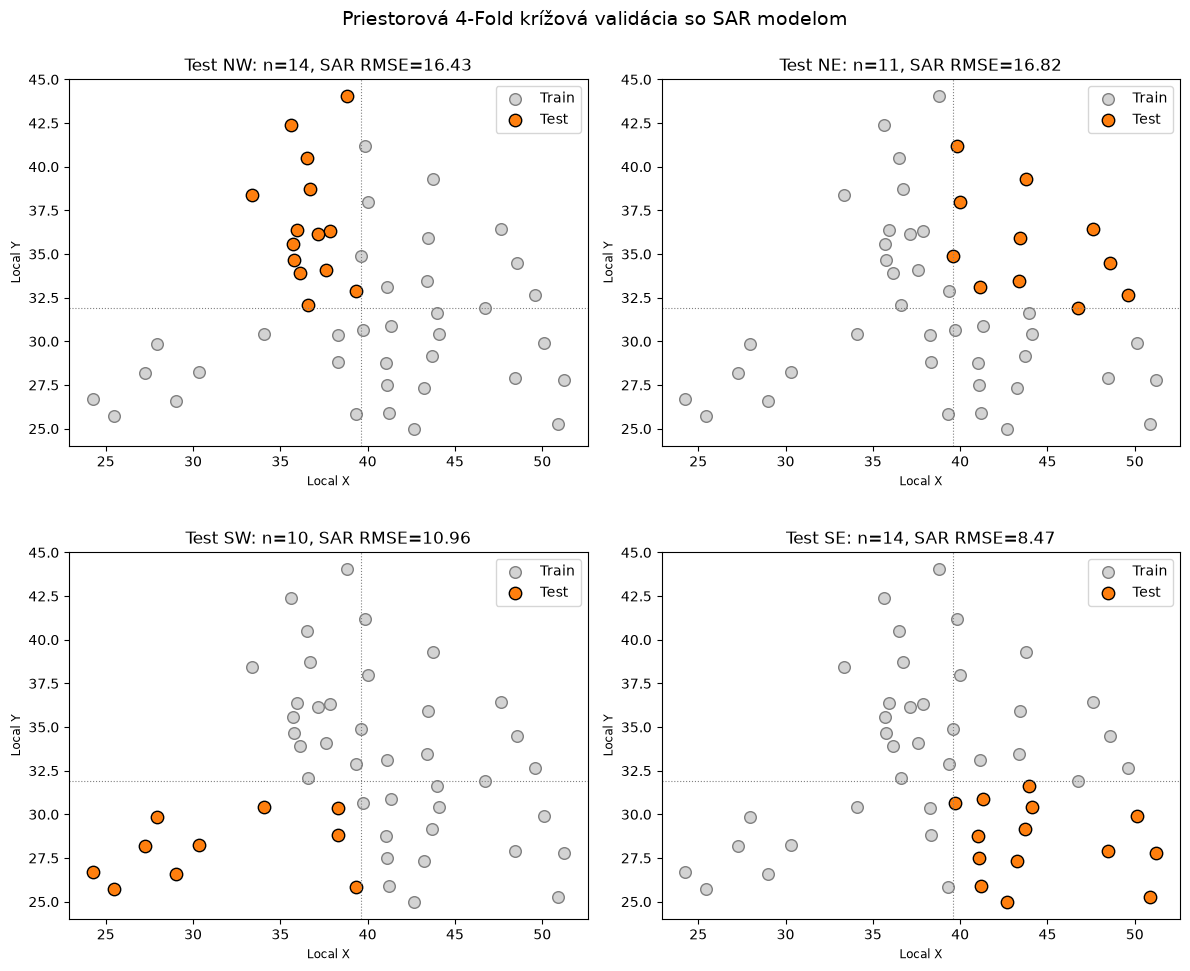

Fold scores:
             n_test      MAE     RMSE
Block Model                          
NW    OLS        14 11.56120 15.68649
      SAR        14 11.42724 16.43350
NE    OLS        11  7.74639  9.48180
      SAR        11 12.66169 16.82218
SW    OLS        10 11.61945 13.72286
      SAR        10  8.80065 10.95991
SE    OLS        14  7.53377  8.78370
      SAR        14  7.34275  8.47496
Pooled out-of-fold errors (each area predicted once):
         MAE     RMSE
OLS  9.56601 12.28670
SAR 10.00133 13.62803
Fold audit:
       Train  Test       rho  Overlap  Test-to-train weight share
Block                                                            
NW        35    14  0.463462        0                    0.125000
NE        38    11  0.707186        0                    0.363636
SW        39    10  0.375476        0                    0.275000
SE        35    14  0.493079        0                    0.232143

Celkové RMSE: 13.63


,POLYID,block,CRIME,pred_crime_sar,pred_crime_ols
0,1,NW,15.73,29.398527,21.872554
1,2,NW,18.80,27.209051,21.010633
2,3,NE,30.63,37.009576,37.921600
3,4,NW,32.39,52.455896,54.927301
4,5,NE,50.73,50.042563,46.260689
5,6,NE,26.07,32.032997,36.812432
6,7,NW,0.18,50.878768,44.185114
7,8,NW,38.43,47.335940,41.087253
8,9,NE,30.52,34.894596,24.499374
9,10,NE,34.00,-7.376086,12.122575


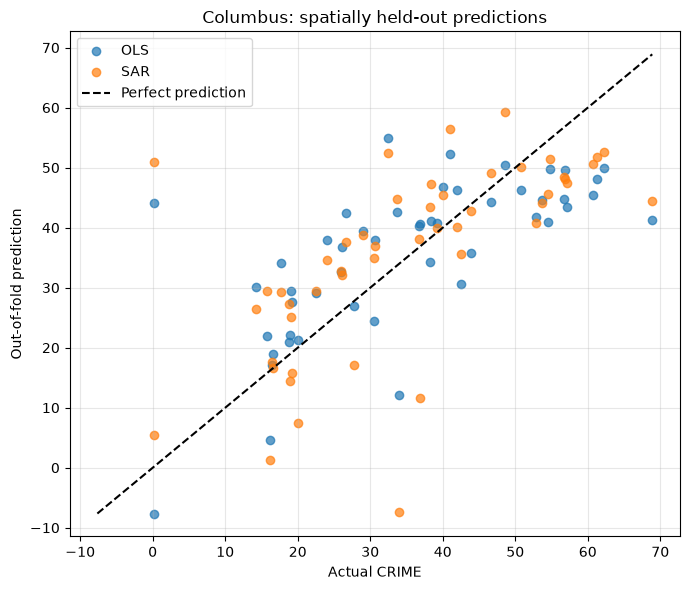

In [7]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import libpysal
from spreg import ML_Lag

# Pomocné funkcie pre predikciu OLS a SAR
def predict_ols(betas, X_test):
    X = np.column_stack([np.ones(len(X_test)), X_test])
    return (X @ betas).flatten()

def predict_sar(rho, betas, X_test, W_TT, W_TR, y_train):
    X = np.column_stack([np.ones(len(X_test)), X_test])
    return np.linalg.solve(
        np.eye(len(X_test)) - rho * W_TT,
        X @ betas + rho * W_TR @ y_train.reshape(-1, 1)
    ).flatten()

# TODO 1:
# Vypočítajte medián súradníc X a Y.
# Rozdeľte mesto na štyri kvadranty: NW, NE, SW, SE.
# Každému pozorovaniu priraďte geografický blok.

# med_x = ...
# med_y = ...
med_x = data['X'].median()
med_y = data['Y'].median()

def assign_quadrant(row):
    # TODO: Podľa súradníc X a Y vráťte
    # 'NE', 'NW', 'SE' alebo 'SW'.
    north_south = 'N' if row['Y'] >= med_y else 'S'
    east_west = 'E' if row['X'] >= med_x else 'W'
    return north_south + east_west
    
data = data.reset_index(drop=True)    
data['block'] = data.apply(assign_quadrant, axis=1)

blocks = ['NW', 'NE', 'SW', 'SE']

# Stĺpec na uloženie predikcií
data['pred_crime_sar'] = np.nan
data['pred_crime_ols'] = np.nan
cv_rows, cv_audit_rows = [], []

# Priestorové váhy pre celé mesto (k=4) s KNN a riadková štandardizácia.
# Potrebujeme poznať aj priestorové vzťahy medzi testom a tréningom.
w_full = knn_weights(data, k=4)
w_full.transform = 'R'
W = w_full.sparse.tocsr()

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# 2. Priestorová krížová validácia
axes = axes.flatten()

for i, (ax, b) in enumerate(zip(axes, blocks), 1):

    # TODO 2:
    # Vyberte tri bloky na tréning a jeden na testovanie.

    # train = ...
    # test = ...
    train = data.loc[data['block'].ne(b)].copy()
    test = data.loc[data['block'].eq(b)].copy()
    if test.empty or len(train) <= 4:
        raise ValueError('A spatial fold is empty or too small.')

    train_idx = train.index.to_numpy()
    test_idx = test.index.to_numpy()

    # TODO 3:
    # Vytvorte KNN váhy pre tréningové dáta (k=4).
    # Vykonajte riadkovú štandardizáciu.

    # w_train = ...
    # w_train.transform = ...
    w_train = knn_weights(train, k=4)

    y_train = train['CRIME'].values
    X_train = train[['INC', 'HOVAL']].values

    # TODO 4:
    # Natrénujte model ML_Lag.
    # Extrahujte a vypíšte rho a regresné koeficienty.
    # Posledná položka sar_fold.betas predstavuje rho.

    # sar_fold = ...

    # rho = ...
    # betas = ...
    sar_fold = fit_spatial(ML_Lag, y_train, X_train, w_train, method='full', spat_impacts=None,
                           name_y='CRIME', name_x=['INC', 'HOVAL'], name_ds=f'Columbus training excluding {b}')
    rho, betas = sar_coefficients(sar_fold, n_features=2)
    ols_fold = fit_spatial(spreg.OLS, y_train, X_train, w_train, nonspat_diag=False,
                           name_y='CRIME', name_x=['INC', 'HOVAL'])

    print(f"\nTest: {b}")
    # TODO 5: Vypíšte rho a beta koeficienty.
    print(f'rho={rho:.6f}; beta (constant, INC, HOVAL)={betas.ravel()}')

    # Blokové rozdelenie matice váh
    W_TT = W[test_idx, :][:, test_idx].toarray()
    W_TR = W[test_idx, :][:, train_idx].toarray()
    X_test = test[['INC', 'HOVAL']].values

   # TODO 6:
   # Pomocou funkcie predict_sar() vypočítajte predikcie
   # pre testovací blok s využitím rho, betas, X_test,
   # W_TT, W_TR a y_train.
   # Predikcie uložte do stĺpca data['pred_crime_sar'].

   # y_pred = ...
   # data.loc[...] = ...
    y_pred = predict_sar(rho, betas, X_test, W_TT, W_TR, y_train)
    y_pred_ols = predict_ols(ols_fold.betas, X_test)
    data.loc[test_idx, 'pred_crime_sar'] = y_pred
    data.loc[test_idx, 'pred_crime_ols'] = y_pred_ols
    for label, prediction in [('OLS', y_pred_ols), ('SAR', y_pred)]:
        cv_rows.append({'Block': b, 'Model': label, 'n_test': len(test),
                        **error_scores(test.CRIME.to_numpy(), prediction)})
    cv_audit_rows.append({'Block': b, 'Train': len(train), 'Test': len(test), 'rho': rho,
                          'Overlap': len(set(train_idx) & set(test_idx)),
                          'Test-to-train weight share': float(W_TR.sum(axis=1).mean())})

    # RMSE pre aktuálny blok
    rmse_fold = np.sqrt(
        np.mean((test['CRIME'].values - y_pred) ** 2)
    )

    print(f"RMSE: {rmse_fold:.2f}")

    # TODO 7:
    # Zobrazte tréningové a testovacie pozorovania
    train.plot(ax=ax, color='lightgray', edgecolor='gray', markersize=70, label='Train')
    test.plot(ax=ax, color='tab:orange', edgecolor='black', markersize=80, label='Test')
    ax.axvline(med_x, color='gray', linestyle=':', linewidth=0.8)
    ax.axhline(med_y, color='gray', linestyle=':', linewidth=0.8)
    ax.set_title(f'Test {b}: n={len(test)}, SAR RMSE={rmse_fold:.2f}')
    ax.set_xlabel('Local X'); ax.set_ylabel('Local Y')
    ax.legend()


plt.suptitle(
    "Priestorová 4-Fold krížová validácia so SAR modelom",
    fontsize=14
)
plt.tight_layout()
plt.show()

# TODO 8:
# Vytvorte DataFrame predictions_table, ktorý obsahuje:
# - POLYID: identifikátor okrsku
# - block: geografický kvadrant
# - CRIME: skutočná kriminalita
# - pred_crime_sar: predikovaná kriminalita
# Zobrazte prvých 15 riadkov tabuľky.

# predictions_table = pd.DataFrame({})
predictions_table = data[['POLYID', 'block', 'CRIME', 'pred_crime_sar', 'pred_crime_ols']].copy()
cv_scores = pd.DataFrame(cv_rows).set_index(['Block', 'Model'])
cv_audit = pd.DataFrame(cv_audit_rows).set_index('Block')
cv_overall_scores = pd.DataFrame({
    'OLS': error_scores(data.CRIME, data.pred_crime_ols),
    'SAR': error_scores(data.CRIME, data.pred_crime_sar),
}).T
print('Fold scores:'); print(cv_scores.to_string(float_format=lambda value: f'{value:.5f}'))
print('Pooled out-of-fold errors (each area predicted once):')
print(cv_overall_scores.to_string(float_format=lambda value: f'{value:.5f}'))
print('Fold audit:'); print(cv_audit.to_string())

overall_rmse = np.sqrt(
    np.mean(
        (data['CRIME'] - data['pred_crime_sar']) ** 2
    )
)

print(f"\nCelkové RMSE: {overall_rmse:.2f}")
display(predictions_table.head(15))

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(data.CRIME, data.pred_crime_ols, label='OLS', alpha=0.7)
ax.scatter(data.CRIME, data.pred_crime_sar, label='SAR', alpha=0.7)
limits = np.concatenate([data.CRIME, data.pred_crime_ols, data.pred_crime_sar])
ax.plot([limits.min(), limits.max()], [limits.min(), limits.max()], 'k--', label='Perfect prediction')
ax.set(xlabel='Actual CRIME', ylabel='Out-of-fold prediction', title='Columbus: spatially held-out predictions')
ax.grid(alpha=0.3); ax.legend(); fig.tight_layout(); plt.show()


### Exercise 6 — interpretation

The median X/Y coordinates define four geographically contiguous quadrants. Each area is predicted once from a model fitted to the other three blocks. The training-only KNN matrix is rebuilt with k=4 at each fold. A separate full-city KNN graph supplies the fixed geometry-only connections needed for prediction; its test/train submatrices retain the original row normalization and are **not** renormalized separately.

SAR uses the provided conditional formula: `(I - rho W_TT) y_hat_T = X_T beta + rho W_TR y_R`. The known training outcomes enter the right-hand side, while the held-out outcomes never enter fitting or prediction. Test covariates and locations are assumed known. This is conditional prediction into a held-out spatial block, not an unconditional prediction for a whole city with no known outcomes. The training and full graphs have different neighbor sets; this is the graph-transfer convention specified by the exercise, rather than a single jointly fitted graph.

The table reports fold errors and the pooled error over all 49 out-of-fold predictions. The pooled RMSE is computed from all squared errors, not an unweighted average of fold RMSE values. OLS provides a baseline with the same folds. Geographic separation makes this a more relevant extrapolation check than a random split when the intended task is prediction in an unobserved area.

**Reference results:** pooled out-of-fold RMSE is **12.28670 for OLS** and **13.62803 for SAR**; MAE is **9.56601** and **10.00133** respectively. SAR performs better in SW and SE by RMSE, but OLS wins overall, particularly because SAR's NE error is larger. This demonstrates why improved full-sample AIC and residual diagnostics do not guarantee better spatially held-out predictions.


#### Bonus 2B:

**Cieľ:** Preskúmať priestorovú závislosť dopravných nehôd medzi okrskami New Yorku a porovnať predikčnú schopnosť modelov OLS a SAR na geograficky oddelených testovacích dátach.

1. Príprava a agregácia dát podľa PSČ
  - Zoskupte dopravné nehody podľa poštových smerovacích čísel.
  - Pre každé PSČ vypočítajte celkový počet zaznamenaných nehôd.
  - Vytvorte cieľovú premennú podiel_np, ktorá vyjadruje podiel nehôd, pri ktorých bolo ako príčina uvedené nedanie prednosti v jazde.
  - Vytvorte vysvetľujúce premenné podiel_suv a podiel_taxiky, ktoré vyjadrujú podiel nehôd, pri ktorých bolo ako prvé zaznamenané vozidlo uvedené SUV alebo taxík.
  - Do ďalšej analýzy zahrňte iba oblasti PSČ s minimálne 8 zaznamenanými nehodami.
  - Pre každé PSČ vypočítajte priemernú zemepisnú šírku a dĺžku zaznamenaných nehôd a vytvorte bodový GeoDataFrame so súradnicovým systémom EPSG:4326. 
  - Rozdeľte PSČ podľa geografickej polohy na približne 80 % tréningových a 20 % testovacích pozorovaní.
  - Ako testovaciu množinu vyberte 20 % najvýchodnejšie položených oblastí podľa zemepisnej dĺžky (lon)
      * použite gdf['lon'].quantile(0.80) na určenie hranice
  - Vykreslite obe množiny na mape New Yorku a farebne ich odlíšte.

2. Konštrukcia priestorovej váhovej matice a predikcia s OLS a SAR
  - Reprojektujte bodové dáta do metrického súradnicového systému EPSG:32618.
  - Pomocou libpysal.weights.KNN vytvorte maticu 5 najbližších susedov (k=5) osobitne pre tréningové dáta a celé územie.
  - Vykonajte riadkovú štandardizáciu (transform='R').
  - Odhadnite OLS model pomocou spreg.OLS a SAR model pomocou spreg.ML_Lag.
  - Pomocou pripravených funkcií predict_ols() a predict_sar() vypočítajte predikované hodnoty pre testovacie oblasti.
  - Porovnajte skutočné a predikované hodnoty v tabuľke a grafe.
  - Určte, ktorý model dosiahol nižšiu predikčnú chybu.

### Bonus — definition of the accident-level indicators

One record is one collision (`UNIQUE KEY`). `podiel_np` is the proportion with **Failure to Yield Right-of-Way in any recorded contributing-factor field**, counted once even when multiple vehicles have that factor. The original first-vehicle-only definition is also retained as `podiel_np_prve` for comparison. SUV and taxi indicators use only `VEHICLE TYPE CODE 1`, as required. The dataset's SUV label is the combined category **SPORT UTILITY / STATION WAGON**; it cannot distinguish SUVs from station wagons. TAXI excludes LIVERY VEHICLE.

ZIPs are normalized to five-character strings. Collisions with no usable ZIP are reported and excluded from ZIP aggregation. Missing vehicle types count as not recorded in the specified category, while the denominator remains all recorded collisions in that ZIP. Coordinates are checked against their point geometries before aggregation. The source is the selected 2016 GeoPlot sample, so the target is a within-sample proportion, not an estimate from the full NYC crash population.

Source collisions: 7303; excluded for unusable ZIP: 384.
ZIPs below 8 records: 19; retained ZIPs: 158; collisions in retained ZIPs: 6852.
Longitude 80th percentile: -73.842686; training ZIPs: 126, test ZIPs: 32 (20.3% test).
Target counts before the minimum-ZIP-count filter: any contributing vehicle 5076 ; first vehicle only 5066


,PSC,pocet_nehod,pocet_np,pocet_np_prve,pocet_suv,pocet_taxiky,lat,lon,podiel_np,podiel_np_prve,podiel_suv,podiel_taxiky,sample
0,10001,126,67,65,10,19,40.750310,-73.996473,0.531746,0.515873,0.079365,0.150794,Training
1,10002,77,44,44,14,3,40.717052,-73.989056,0.571429,0.571429,0.181818,0.038961,Training
2,10003,59,37,37,9,8,40.733261,-73.990138,0.627119,0.627119,0.152542,0.135593,Training
3,10004,9,3,3,1,0,40.703883,-74.013462,0.333333,0.333333,0.111111,0.000000,Training
4,10005,8,5,5,0,2,40.706299,-74.008647,0.625000,0.625000,0.000000,0.250000,Training
5,10007,19,12,12,2,4,40.714479,-74.008697,0.631579,0.631579,0.105263,0.210526,Training
6,10009,27,16,16,2,7,40.727664,-73.982617,0.592593,0.592593,0.074074,0.259259,Training
7,10010,46,29,29,6,7,40.739779,-73.985419,0.630435,0.630435,0.130435,0.152174,Training
8,10011,91,52,52,13,8,40.741925,-74.001124,0.571429,0.571429,0.142857,0.087912,Training
9,10012,54,26,26,4,12,40.724944,-73.996750,0.481481,0.481481,0.074074,0.222222,Training


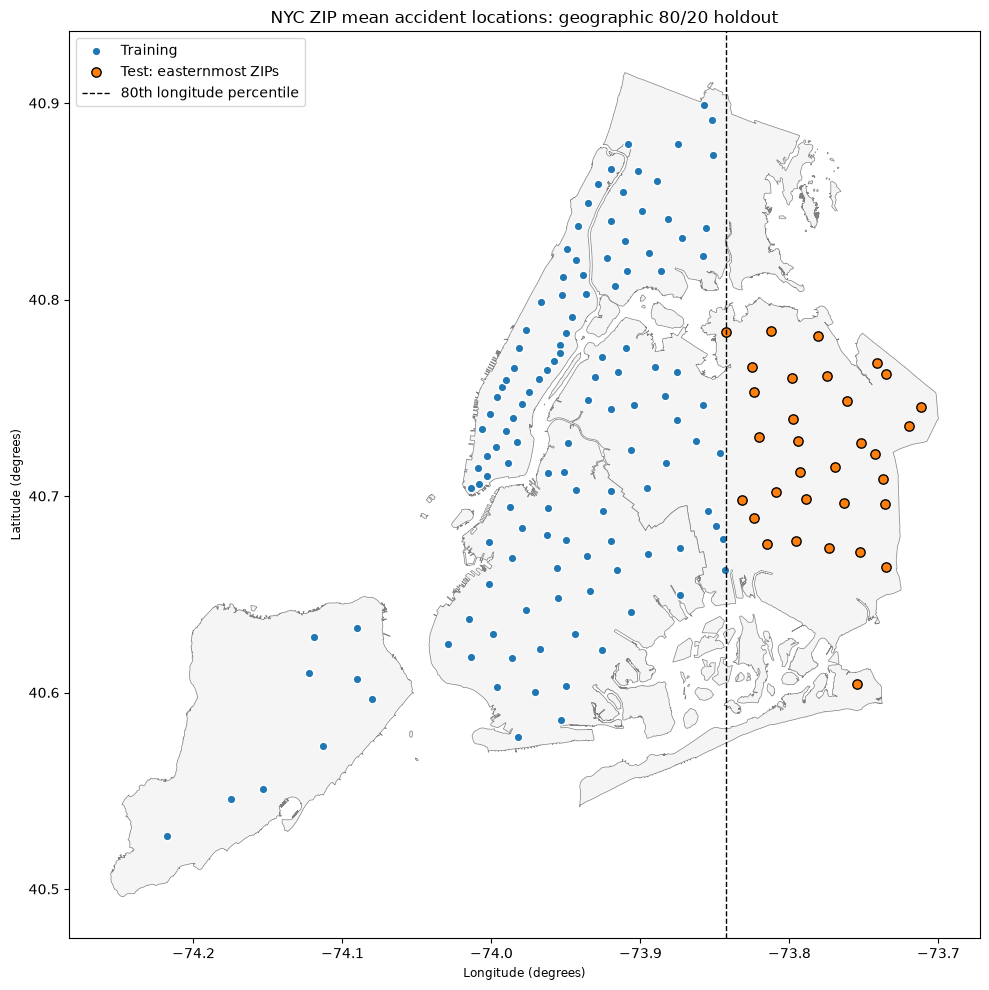

In [8]:
bonus_collisions = nyc_collisions.to_crs('EPSG:4326').copy()
if bonus_collisions['UNIQUE KEY'].isna().any() or bonus_collisions['UNIQUE KEY'].duplicated().any():
    raise ValueError('Missing or duplicate accident identifiers: inspect before aggregation.')
zip_numeric = pd.to_numeric(bonus_collisions['ZIP CODE'], errors='coerce')
valid_zip = zip_numeric.notna() & zip_numeric.between(10000, 99999) & zip_numeric.mod(1).eq(0)
missing_zip_count = int((~valid_zip).sum())
bonus_collisions = bonus_collisions.loc[valid_zip].copy()
bonus_collisions['PSC'] = zip_numeric.loc[valid_zip].astype(int).astype(str).str.zfill(5)
factor_columns = [c for c in bonus_collisions if c.startswith('CONTRIBUTING FACTOR VEHICLE')]
bonus_collisions['is_np'] = bonus_collisions[factor_columns].eq('Failure to Yield Right-of-Way').any(axis=1)
bonus_collisions['is_np_prve'] = bonus_collisions['CONTRIBUTING FACTOR VEHICLE 1'].eq('Failure to Yield Right-of-Way')
bonus_collisions['is_suv'] = bonus_collisions['VEHICLE TYPE CODE 1'].eq('SPORT UTILITY / STATION WAGON')
bonus_collisions['is_taxi'] = bonus_collisions['VEHICLE TYPE CODE 1'].eq('TAXI')
bonus_collisions['lon'] = pd.to_numeric(bonus_collisions.LONGITUDE, errors='raise')
bonus_collisions['lat'] = pd.to_numeric(bonus_collisions.LATITUDE, errors='raise')
if not np.isfinite(bonus_collisions[['lon', 'lat']].to_numpy()).all():
    raise ValueError('Missing or nonfinite accident coordinates.')
np.testing.assert_allclose(bonus_collisions.lon, bonus_collisions.geometry.x, atol=1e-8)
np.testing.assert_allclose(bonus_collisions.lat, bonus_collisions.geometry.y, atol=1e-8)

zip_aggregate = bonus_collisions.groupby('PSC', sort=True).agg(
    pocet_nehod=('UNIQUE KEY', 'size'), pocet_np=('is_np', 'sum'),
    pocet_np_prve=('is_np_prve', 'sum'), pocet_suv=('is_suv', 'sum'), pocet_taxiky=('is_taxi', 'sum'),
    lat=('lat', 'mean'), lon=('lon', 'mean'),
)
for name, count in [('podiel_np', 'pocet_np'), ('podiel_np_prve', 'pocet_np_prve'),
                    ('podiel_suv', 'pocet_suv'), ('podiel_taxiky', 'pocet_taxiky')]:
    zip_aggregate[name] = zip_aggregate[count] / zip_aggregate.pocet_nehod
small_zip_count = int((zip_aggregate.pocet_nehod < 8).sum())
zip_aggregate = zip_aggregate.loc[zip_aggregate.pocet_nehod >= 8].reset_index()
gdf = gpd.GeoDataFrame(zip_aggregate, geometry=gpd.points_from_xy(zip_aggregate.lon, zip_aggregate.lat),
                        crs='EPSG:4326')
longitude_cutoff = gdf['lon'].quantile(0.80)
zip_test_mask = gdf.lon.ge(longitude_cutoff)
gdf['sample'] = np.where(zip_test_mask, 'Test: easternmost ZIPs', 'Training')
print(f'Source collisions: {len(nyc_collisions)}; excluded for unusable ZIP: {missing_zip_count}.')
print(f'ZIPs below 8 records: {small_zip_count}; retained ZIPs: {len(gdf)}; '
      f'collisions in retained ZIPs: {int(gdf.pocet_nehod.sum())}.')
print(f'Longitude 80th percentile: {longitude_cutoff:.6f}; '
      f'training ZIPs: {(~zip_test_mask).sum()}, test ZIPs: {zip_test_mask.sum()} '
      f'({zip_test_mask.mean():.1%} test).')
print('Target counts before the minimum-ZIP-count filter:',
      'any contributing vehicle', int(bonus_collisions.is_np.sum()),
      '; first vehicle only', int(bonus_collisions.is_np_prve.sum()))
display(gdf.drop(columns='geometry').head(15))

fig, ax = plt.subplots(figsize=(10, 10))
nyc_wgs84.plot(ax=ax, color='whitesmoke', edgecolor='gray', linewidth=0.5)
gdf.loc[~zip_test_mask].plot(ax=ax, color='tab:blue', edgecolor='white', markersize=38, label='Training')
gdf.loc[zip_test_mask].plot(ax=ax, color='tab:orange', edgecolor='black', markersize=45, label='Test: easternmost ZIPs')
ax.axvline(longitude_cutoff, color='black', linestyle='--', linewidth=1, label='80th longitude percentile')
ax.set(xlabel='Longitude (degrees)', ylabel='Latitude (degrees)',
        title='NYC ZIP mean accident locations: geographic 80/20 holdout')
ax.legend(loc='upper left')
fig.tight_layout()
plt.show()

### Bonus — spatial weights and held-out prediction

The ZIP location is the mean coordinate of its recorded collisions, not the geometric centroid of an official postal polygon. The eastern test set is selected with `lon >= quantile(0.80)`; quantile interpolation and ties can make its size differ slightly from exactly 20%. Projection takes place after this split so that its geographic definition remains explicit.

Fit OLS and SAR on training ZIPs only. Build k=5 row-standardized KNN weights separately for training ZIPs and the full area. Full weights depend on locations only and are partitioned in the exact full-data row order. The provided prediction functions receive test predictors and known training outcomes, never test outcomes.

ML_Lag
Weight graph components: training 1 ; full 1
OLS coefficients (constant, SUV share, taxi share): [ 0.6530269   0.45819349 -0.56856323]
SAR coefficients (constant, SUV share, taxi share): [ 0.22844152  0.34932447 -0.12791089] ; rho: 0.5969328273046635
Training AIC: OLS -176.56657068056427 ; SAR -211.42558211082576
Training OLS diagnostics: Both classical tests reject; robust tests do not select a unique simple model.
Geographically held-out scores (share units; multiply by 100 for percentage points):
                            MAE     RMSE
Model                                   
OLS                    0.104606 0.117215
SAR                    0.096280 0.110105
Training-mean baseline 0.147586 0.158476
Lower RMSE between OLS/SAR: SAR
Lower MAE between OLS/SAR: SAR
Out-of-range linear predictions: {'OLS': 0, 'SAR': 0}
Mean full-graph weight connecting a test ZIP to training ZIPs: 0.07500000000000001


,PSC,pocet_nehod,podiel_np,podiel_suv,podiel_taxiky,pred_OLS,pred_SAR,error_OLS,error_SAR
67,11004,8,0.875000,0.125000,0.000000,0.710301,0.730666,-0.164699,-0.144334
112,11354,192,0.786458,0.270833,0.005208,0.774160,0.815335,-0.012299,0.028876
113,11355,195,0.866667,0.364103,0.025641,0.805278,0.848517,-0.061389,-0.018150
114,11356,47,0.829787,0.191489,0.021277,0.728669,0.801569,-0.101118,-0.028218
115,11357,68,0.882353,0.205882,0.014706,0.739000,0.786608,-0.143353,-0.095745
116,11358,94,0.851064,0.287234,0.010638,0.778587,0.813025,-0.072477,-0.038039
117,11360,18,0.944444,0.333333,0.000000,0.805758,0.810183,-0.138686,-0.134261
118,11361,52,0.769231,0.250000,0.000000,0.767575,0.786365,-0.001655,0.017134
119,11362,16,0.812500,0.250000,0.000000,0.767575,0.770751,-0.044925,-0.041749
120,11363,9,0.888889,0.222222,0.000000,0.754848,0.765034,-0.134041,-0.123855


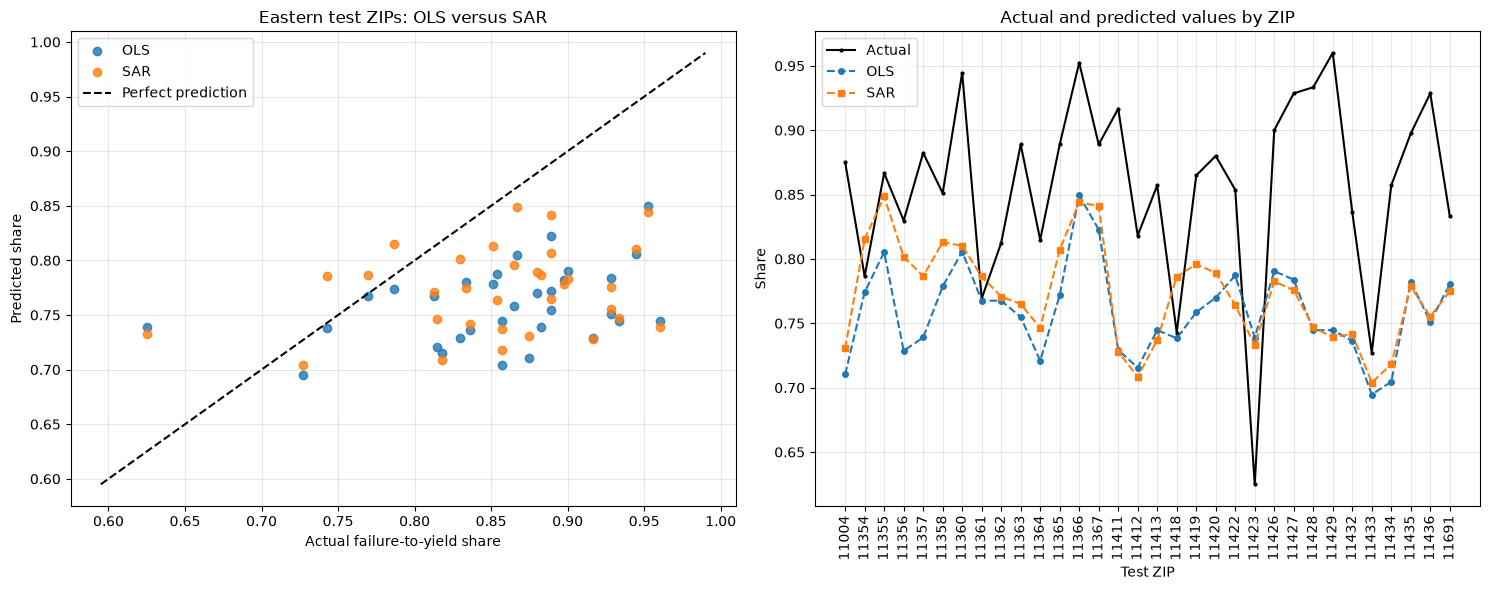

In [9]:
zip_metric = gdf.to_crs('EPSG:32618')
zip_train = zip_metric.loc[~zip_test_mask].copy()
zip_test = zip_metric.loc[zip_test_mask].copy()
zip_w_train = knn_weights(zip_train, k=5)
zip_w_full = knn_weights(zip_metric, k=5)
zip_W = zip_w_full.sparse.tocsr()
zip_train_idx = zip_train.index.to_numpy()
zip_test_idx = zip_test.index.to_numpy()
zip_W_TT = zip_W[zip_test_idx, :][:, zip_test_idx].toarray()
zip_W_TR = zip_W[zip_test_idx, :][:, zip_train_idx].toarray()
zip_predictors = ['podiel_suv', 'podiel_taxiky']
zip_y_train = zip_train.podiel_np.to_numpy().reshape(-1, 1)
zip_X_train = zip_train[zip_predictors].to_numpy()
zip_X_test = zip_test[zip_predictors].to_numpy()

zip_ols = fit_spatial(spreg.OLS, zip_y_train, zip_X_train, zip_w_train, spat_diag=True, moran=True,
                      name_y='podiel_np', name_x=zip_predictors, name_w='ZIP KNN 5 training / R',
                      name_ds='NYC collision sample: western training ZIPs')
zip_sar = fit_spatial(spreg.ML_Lag, zip_y_train, zip_X_train, zip_w_train, method='full',
                      spat_impacts=None, name_y='podiel_np', name_x=zip_predictors,
                      name_w='ZIP KNN 5 training / R', name_ds='NYC collision sample: western training ZIPs')
zip_rho, zip_betas = sar_coefficients(zip_sar, n_features=2)
print('Weight graph components:', 'training', zip_w_train.n_components, '; full', zip_w_full.n_components)
print('OLS coefficients (constant, SUV share, taxi share):', zip_ols.betas.ravel())
print('SAR coefficients (constant, SUV share, taxi share):', zip_betas.ravel(), '; rho:', zip_rho)
print('Training AIC:', 'OLS', zip_ols.aic, '; SAR', zip_sar.aic)
print('Training OLS diagnostics:', diagnostic_recommendation(zip_ols))

zip_pred_ols = predict_ols(zip_ols.betas, zip_X_test)
zip_pred_sar = predict_sar(zip_rho, zip_betas, zip_X_test, zip_W_TT, zip_W_TR, zip_y_train)
# Only now reveal held-out target shares for scoring.
zip_actual = zip_test.podiel_np.to_numpy()
bonus_predictions_table = zip_test[['PSC', 'pocet_nehod', 'podiel_np', 'podiel_suv', 'podiel_taxiky']].copy()
bonus_predictions_table['pred_OLS'] = zip_pred_ols
bonus_predictions_table['pred_SAR'] = zip_pred_sar
bonus_predictions_table['error_OLS'] = zip_pred_ols - zip_actual
bonus_predictions_table['error_SAR'] = zip_pred_sar - zip_actual
bonus_predictions_table = bonus_predictions_table.sort_values('PSC')
bonus_scores = pd.DataFrame({
    'OLS': error_scores(zip_actual, zip_pred_ols),
    'SAR': error_scores(zip_actual, zip_pred_sar),
    'Training-mean baseline': error_scores(zip_actual, np.repeat(zip_y_train.mean(), len(zip_actual))),
}).T.rename_axis('Model')
print('Geographically held-out scores (share units; multiply by 100 for percentage points):')
print(bonus_scores.to_string(float_format=lambda value: f'{value:.6f}'))
print('Lower RMSE between OLS/SAR:', bonus_scores.loc[['OLS', 'SAR'], 'RMSE'].idxmin())
print('Lower MAE between OLS/SAR:', bonus_scores.loc[['OLS', 'SAR'], 'MAE'].idxmin())
print('Out-of-range linear predictions:',
      {name: int(((p < 0) | (p > 1)).sum()) for name, p in [('OLS', zip_pred_ols), ('SAR', zip_pred_sar)]})
print('Mean full-graph weight connecting a test ZIP to training ZIPs:', zip_W_TR.sum(axis=1).mean())
display(bonus_predictions_table)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for label, prediction, color in [('OLS', zip_pred_ols, 'tab:blue'), ('SAR', zip_pred_sar, 'tab:orange')]:
    axes[0].scatter(zip_actual, prediction, label=label, color=color, alpha=0.8)
values = np.concatenate([zip_actual, zip_pred_ols, zip_pred_sar])
low, high = max(0, values.min() - 0.03), min(1.05, values.max() + 0.03)
axes[0].plot([low, high], [low, high], 'k--', label='Perfect prediction')
axes[0].set(xlabel='Actual failure-to-yield share', ylabel='Predicted share',
             title='Eastern test ZIPs: OLS versus SAR')
axes[0].legend(); axes[0].grid(alpha=0.3)
positions = np.arange(len(bonus_predictions_table))
for column, label, style in [('podiel_np', 'Actual', 'k.-'), ('pred_OLS', 'OLS', 'o--'), ('pred_SAR', 'SAR', 's--')]:
    axes[1].plot(positions, bonus_predictions_table[column], style, markersize=4, label=label)
axes[1].set_xticks(positions, bonus_predictions_table.PSC, rotation=90)
axes[1].set(xlabel='Test ZIP', ylabel='Share', title='Actual and predicted values by ZIP')
axes[1].legend(); axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

zip_aggregate.to_csv(data_dir / 'nyc_zip_aggregates.csv', index=False)
bonus_predictions_table.to_csv(data_dir / 'nyc_zip_test_predictions.csv', index=False)
bonus_scores.to_csv(data_dir / 'nyc_zip_model_scores.csv')

### Bonus — interpretation

The reported winner is selected by held-out RMSE between OLS and SAR, with MAE also reported. Training AIC and a significant spatial coefficient do not establish superior prediction in eastern ZIPs. A training-mean baseline provides a further check against unnecessary model complexity. Scores weight each ZIP equally; ZIPs have different accident denominators, so share precision varies even after requiring at least eight records.

SAR's conditional prediction accounts for links among test ZIPs through `(I-rho W_TT)^(-1)` and known neighboring training shares through `rho W_TR y_train`. No observed test target enters either term. Information about training neighbors is assumed available for this prediction task. Some test ZIPs can connect entirely to other test ZIPs; their test-to-training weight is zero, but the simultaneous system still propagates any boundary information reachable through the test graph.

Both fitted models are linear approximations to a bounded proportion. Raw predictions are evaluated without clipping; any values outside [0,1] are counted explicitly. Coefficients describe associations in this selected accident sample, not a causal effect of SUVs or taxis. Missing first-vehicle types remain in the denominator, so these are shares of records **recorded as** each type. The alternate `podiel_np_prve` column documents how a first-vehicle-only target would differ; it is not substituted after observing test errors.

**Reference results:** 384 collisions have no usable ZIP. After excluding 19 ZIPs with fewer than eight records, **158 ZIPs** remain, covering **6852 collisions**. The longitude boundary is **-73.842686**: **126 training ZIPs** and **32 eastern test ZIPs** (20.3%). SAR estimates rho = **0.596933**. Neither model produces an out-of-range prediction on this test set.

| Model | MAE | RMSE |
| --- | ---: | ---: |
| OLS | 0.104606 | 0.117215 |
| SAR | 0.096280 | 0.110105 |
| Training-mean baseline | 0.147586 | 0.158476 |

**SAR has lower held-out MAE and RMSE than OLS** for the requested NYC task. Its RMSE is approximately **11.01 percentage points**, compared with **11.72** for OLS. Both improve on the training-mean baseline. The plot also shows that both models tend to underestimate the largest observed shares. This is a result for this split and target definition; it does not imply SAR will always outperform OLS, as the Columbus block evaluation illustrates.

### API and data references

- [statsmodels KalmanFilter](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.kalman_filter.KalmanFilter.html)
- [GeoPlot teaching data](https://github.com/ResidentMario/geoplot-data) and [Columbus source CSV](https://raw.githubusercontent.com/GeoDaCenter/GeoDaSpace/master/econometrics/examples/columbus.csv)
- [GeoPandas spatial join](https://geopandas.org/en/stable/docs/reference/api/geopandas.sjoin.html)
- [PySAL spatial lag estimation](https://pysal.org/spreg/notebooks/13_ML_estimation_spatial_lag.html) and [ML_Lag](https://pysal.org/spreg/generated/spreg.ML_Lag.html)